# 03 — Microglia states from the Prinz myeloid atlas (Tangram) and compartments

Transfering the microglia state modules (Surveillance, Inflammation, Phagocytosis, IFN, MHC,
Proliferation, Neuroprotection, Cytokine) from Mouse_Myeloid_atlas_v1.h5ad to the Xenium microglia, then combining the states
with the CellCharter compartments.

### Which atlas cells to keep (decision)
What the Xenium data contain (notebook 01 / checks on 2026-10-21):
- The Xenium "Microglia" class (28,916 cells) is pure microglia: P2ry12 in 95% of cells, Cx3cr1 88%, Tmem119 63%;
  border-associated macrophage (BAM) markers are almost absent (Mrc1 1%, Lyve1 0.1%, Cd163 0.2%, Pf4 0.1%, Ms4a7 0.3%), Ccr2 2.7%.
- T cells are rare, not absent : 242 of 980k cells (~2.5 per 10k; shuffle null ~4),
  called from co-expression of ≥ 2 core genes (Cd3d/e/g, Cd247, Cd2, Cd8a/b1, Itk, Cxcr6). They are CD8 / Cxcr6
  tissue-resident-type cells, mostly at the meninges, ventricles and along vessels, and carry their neighbours' labels
  (endothelial / leptomeningeal 55%, astrocyte 18%, DA-OL 15%), not the Microglia label. Not more numerous in responders.
  B / plasma cells: Ms4a1 0 and Jchain 0.1% of Xenium microglia. Ly6c2, Nkg7 and S100a8 are not on the panel.
- (Probe warning: Trbc1 and Ighm are dominated by off-target signal in cortical neurons; do not use them
  to call T or B cells.)
- Tangram has to place every reference cell somewhere, so reference populations that are missing from the query get
  forced onto the wrong cells.

Choice:
1. **Main run**: query = Xenium microglia; reference = atlas **Microglia only**; label = `Module_label`.
2. **Sanity run** (to implement?): reference = Microglia + CAM + MDM, label = `Subclass_label`. Few Xenium microglia should
   be called CAM/MDM, which confirms the query is microglia.
3. Lymphocytes, NK, plasmablasts, granulocytes and cDC1 are dropped: they are not in the Microglia query.
4. Possible extension: BAMs. Mrc1 ≥ 2 counts in ~4,000 cells, mostly annotated Endothelial / Astrocytes
   (perivascular macrophages merged with vessels). They could be gated by markers and mapped with CAM/MDM.

### Tangram settings
- `mode='constrained'`, `target_count` = microglia in the section, `density_prior='uniform'` (single-cell resolution).
  In `'cells'` mode every atlas cell must be placed, so the reference composition becomes a prior on the state
  proportions. `'constrained'` selects which atlas cells to use, so the proportions come from the Xenium data.
- The atlas is subsampled (max 3,000 cells per state, ~6× the microglia of the largest section), and the same reference
  is used for all sections.
- Each section is mapped separately.
- Training genes: atlas state markers ∩ panel; other shared genes are held out for validation.


In [1]:
import logging
import inspect
import numpy as np
import pandas as pd
import anndata as ad
import scanpy as sc
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from scipy.spatial import cKDTree
import tangram as tg
import compartment_stats as cs

logging.getLogger('lightning.pytorch').setLevel(logging.ERROR)

DATA = '../data/adata_5k_cellcharter.h5ad'
ATLAS = '../data/Mouse_Myeloid_atlas_v1.h5ad'
RES = '../results/cellcharter/tangram'
SAMPLE, COND, COMP, CT_WORK, TP = 'sample_id', 'condition', 'compartment', 'cell_class_work', 'timepoint'
RESP = 'responder_status'        # control / responder / non-responder (CM_README.md finding 1; set in notebook 01)
LABEL = 'Module_label'
REF_SUBCLASSES = ['Microglia']        # sanity run: ['Microglia', 'CAM', 'MDM'] with LABEL = 'Subclass_label'
MAX_PER_STATE = 3000
DEVICE = 'cuda:0' if torch.cuda.is_available() else 'cpu'

import os; os.makedirs(RES, exist_ok=True)
print(tg.__version__ if hasattr(tg, '__version__') else 'tangram', DEVICE)
print(inspect.signature(tg.pp_adatas))
print(inspect.signature(tg.map_cells_to_space))

1.0.4 cuda:0
(adata_sc, adata_sp, genes=None, gene_to_lowercase=True)
(adata_sc, adata_sp, cv_train_genes=None, cluster_label=None, mode='cells', device='cpu', learning_rate=0.1, num_epochs=1000, scale=True, lambda_d=0, lambda_g1=1, lambda_g2=0, lambda_r=0, lambda_count=1, lambda_f_reg=1, target_count=None, random_state=None, verbose=True, density_prior='rna_count_based')


## 1. Query: Xenium microglia

In [2]:
full = ad.read_h5ad(DATA, backed='r')
obs_all = full.obs.copy()
spatial_all = full.obsm['spatial']
mg_mask = (obs_all[CT_WORK] == 'Microglia').values

q = full[mg_mask].to_memory()
del q.layers['counts']                      # X (log-normalized) is what Tangram uses
q.obsm = {'spatial': q.obsm['spatial']}
print(q)
print(q.obs[SAMPLE].value_counts())

AnnData object with n_obs × n_vars = 28916 × 5101
    obs: 'x_centroid', 'y_centroid', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method', 'run', 'n_genes_by_counts', 'n_counts', 'n_genes', 'leiden_0.5', 'leiden_1', 'leiden_2', 'cell_class', 'sample_id', 'age', 'sex', 'genotype', 'condition', 'cell_type', 'cell_id', 'rbd_domain_0.1', 'rbd_domain_0.2', 'rbd_domain_0.5', 'rbd_domain_1.0', 'RBD_compartment', 'RBD_compartment_simplified', 'leiden_1.5', 'leiden_2.1', 'leiden_2.3', 'leiden_2.5', 'leiden_3', 'cytetype_annotation_leiden_3', 'cytetype_cellOntologyTerm_leiden_3', 'novae_sid', 'neighborhood_valid', 'novae_leaves', 'novae_domains_15', 'novae_domains_30', 'novae_domains_25', 'novae_domains_20', 'novae_domains_50', 'cell_class_updated', 'compartment', 'cell_class_work', 'timepoint', 'responder_s

## 2. Reference: atlas microglia

In [3]:
atlas = ad.read_h5ad(ATLAS, backed='r')
print('atlas X log-normalized to 1e4:', np.expm1(atlas.X[:5].toarray()).sum(1).round(0))

aobs = atlas.obs[atlas.obs['Subclass_label'].isin(REF_SUBCLASSES)]
keep = (aobs.groupby(LABEL, observed=True, group_keys=False)
        .apply(lambda d: d.sample(min(len(d), MAX_PER_STATE), random_state=0)).index)
shared = [g for g in q.var_names if g in set(atlas.var_names)]
ref = atlas[keep, shared].to_memory()
ref.layers.clear()
print(ref)
print(pd.crosstab(ref.obs[LABEL], ref.obs['Condition']))
print(f'shared genes: {len(shared)} / {q.n_vars} (missing ones are mostly old symbols: Sept*, March*, Hist*)')

atlas X log-normalized to 1e4: [10000. 10000. 10000. 10000. 10000.]
AnnData object with n_obs × n_vars = 19788 × 5048
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'condition', 'Species', 'Region', 'percent.mt', 'Subclass_label', 'Condition', 'Tissue', 'Context_stagewise', 'Context_stagewise_Controls_merged', 'Subclass_id', 'Subclass_id_label', 'Subclass_color', 'Tissue_label', 'Tissue_id', 'Tissue_id_label', 'Tissue_color', 'Condition_label', 'Condition_color', 'Condition_id', 'Condition_id_label', 'Module_label', 'Module_id', 'Module_color', 'Module_id_label', 'relabelled_clusters', 'Context_region'
    obsm: 'X_pca', 'X_umap'
    layers: None (.X)
Condition        Homeostatic  Non-homeostatic
Module_label                                 
Cytokine                  24              189
IFN                       93             2907
Inflammation             257             2743
MHC                       67             2375
Neuroprotection            2             2131
Phagocytosis

## 3. Training and held-out genes
Training genes: top 100 Wilcoxon markers per state in the atlas, restricted to the panel. Held-out genes: other shared
genes detected in ≥ 5% of the Xenium microglia; used only for validation.

In [6]:
sc.tl.rank_genes_groups(ref, LABEL, method='wilcoxon', n_genes=100)
rg = sc.get.rank_genes_groups_df(ref, group=None)
train_genes = sorted(set(rg.loc[rg['logfoldchanges'] > 0.5, 'names']))

detected = np.asarray((q.X > 0).mean(0)).ravel() >= 0.05
shared_set, train_set = set(shared), set(train_genes)
test_genes = [g for g, d in zip(q.var_names, detected) if d and g in shared_set and g not in train_set]
print(f'training genes: {len(train_genes)} | held-out genes: {len(test_genes)}')
print(rg.groupby('group', observed=True).head(8).groupby('group', observed=True)['names'].apply(', '.join))

training genes: 541 | held-out genes: 1768
group
Cytokine           Ccl12, Tnf, Icam1, Gpr84, Birc3, Nfe2l2, Nfkb1...
IFN                Ifi204, Oasl2, Stat2, Nlrc5, Eif2ak2, Zup1, Sa...
Inflammation       Ptgds, Apod, Dst, Fkbp5, Pten, Mycbp2, Zfhx3, ...
MHC                 B2m, Ctss, H2-D1, Hexb, H2-K1, Trem2, Cd74, Cd81
Neuroprotection    Abca1, Gpnmb, Apobec1, Igf1, Myo1e, Myo5a, Atx...
Phagocytosis       Plxdc2, Cacna1a, Cadm1, Myo1e, Ank, Cd9, Hif1a...
Proliferation      Rad51b, Ly86, Top2a, Diaph3, Brip1, Ezh2, Cbx5...
Surveillance       Selplg, Siglech, Gpr34, Elmo1, Numb, P2ry12, T...
Name: names, dtype: object


## 4. Mapping, one section at a time

In [8]:
def cosine_per_gene(pred, meas):
    num = (pred * meas).sum(0)
    den = np.linalg.norm(pred, axis=0) * np.linalg.norm(meas, axis=0)
    return np.where(den > 0, num / den, np.nan)

onehot = pd.get_dummies(ref.obs[LABEL]).astype(float)
X_ref_test = ref[:, test_genes].X
X_ref_train = ref[:, train_genes].X

probs, qc = [], []
for s in q.obs[SAMPLE].cat.categories:
    sp_s = q[q.obs[SAMPLE] == s].copy()
    sc_s = ref.copy()
    tg.pp_adatas(sc_s, sp_s, genes=train_genes)               # works on copies: Tangram lower-cases gene names
    ad_map = tg.map_cells_to_space(sc_s, sp_s, mode='constrained', target_count=sp_s.n_obs,
                                   density_prior='uniform', num_epochs=1000, device=DEVICE,
                                   random_state=0, verbose=False)
    W = ad_map.X * ad_map.obs['F_out'].values[:, None]       # atlas cells x Xenium cells, weighted by the cell filter

    P = pd.DataFrame(W.T @ onehot.values, index=sp_s.obs_names, columns=onehot.columns)
    probs.append(P.div(P.sum(1), axis=0))

    # validation: expression of each Xenium cell predicted from the atlas cells mapped to it
    norm = W.sum(0)[:, None]
    score = {}
    for name, Xr, genes in [('train', X_ref_train, train_genes), ('test', X_ref_test, test_genes)]:
        pred = np.asarray((Xr.T @ W).T) / norm
        meas = q[sp_s.obs_names, genes].X.toarray()    # q keeps the original gene names
        score[name] = np.nanmedian(cosine_per_gene(pred, meas))
    qc.append({SAMPLE: s, 'n_microglia': sp_s.n_obs, 'atlas_cells_used (F>0.5)': int((ad_map.obs['F_out'] > 0.5).sum()),
               'median cosine train': score['train'], 'median cosine held-out': score['test']})
    print(qc[-1])
    del ad_map, W, sc_s, sp_s
    torch.cuda.empty_cache()

qc = pd.DataFrame(qc).set_index(SAMPLE)
qc.to_csv(f'{RES}/tangram_qc_per_section.csv')

INFO:root:539 training genes are saved in `uns``training_genes` of both single cell and spatial Anndatas.
INFO:root:4372 overlapped genes are saved in `uns``overlap_genes` of both single cell and spatial Anndatas.
INFO:root:uniform based density prior is calculated and saved in `obs``uniform_density` of the spatial Anndata.
INFO:root:rna count based density prior is calculated and saved in `obs``rna_count_based_density` of the spatial Anndata.
INFO:root:Allocate tensors for mapping.
INFO:root:Begin training with 539 genes and uniform density_prior in constrained mode...
INFO:root:Saving results..


{'sample_id': 'RB4620', 'n_microglia': 2316, 'atlas_cells_used (F>0.5)': 2211, 'median cosine train': np.float32(0.5925975), 'median cosine held-out': np.float32(0.24641189)}


INFO:root:534 training genes are saved in `uns``training_genes` of both single cell and spatial Anndatas.
INFO:root:4335 overlapped genes are saved in `uns``overlap_genes` of both single cell and spatial Anndatas.
INFO:root:uniform based density prior is calculated and saved in `obs``uniform_density` of the spatial Anndata.
INFO:root:rna count based density prior is calculated and saved in `obs``rna_count_based_density` of the spatial Anndata.
INFO:root:Allocate tensors for mapping.
INFO:root:Begin training with 534 genes and uniform density_prior in constrained mode...
INFO:root:Saving results..


{'sample_id': 'RB4658', 'n_microglia': 1920, 'atlas_cells_used (F>0.5)': 1807, 'median cosine train': np.float32(0.5758889), 'median cosine held-out': np.float32(0.25224736)}


INFO:root:537 training genes are saved in `uns``training_genes` of both single cell and spatial Anndatas.
INFO:root:4391 overlapped genes are saved in `uns``overlap_genes` of both single cell and spatial Anndatas.
INFO:root:uniform based density prior is calculated and saved in `obs``uniform_density` of the spatial Anndata.
INFO:root:rna count based density prior is calculated and saved in `obs``rna_count_based_density` of the spatial Anndata.
INFO:root:Allocate tensors for mapping.
INFO:root:Begin training with 537 genes and uniform density_prior in constrained mode...
INFO:root:Saving results..


{'sample_id': 'RB4676', 'n_microglia': 2424, 'atlas_cells_used (F>0.5)': 2313, 'median cosine train': np.float32(0.59526145), 'median cosine held-out': np.float32(0.2540564)}


... (14 outputs left out)

INFO:root:541 training genes are saved in `uns``training_genes` of both single cell and spatial Anndatas.
INFO:root:4559 overlapped genes are saved in `uns``overlap_genes` of both single cell and spatial Anndatas.
INFO:root:uniform based density prior is calculated and saved in `obs``uniform_density` of the spatial Anndata.
INFO:root:rna count based density prior is calculated and saved in `obs``rna_count_based_density` of the spatial Anndata.
INFO:root:Allocate tensors for mapping.
INFO:root:Begin training with 541 genes and uniform density_prior in constrained mode...
INFO:root:Saving results..


{'sample_id': 'RB4403', 'n_microglia': 3783, 'atlas_cells_used (F>0.5)': 3703, 'median cosine train': np.float32(0.6026853), 'median cosine held-out': np.float32(0.26992387)}


INFO:root:540 training genes are saved in `uns``training_genes` of both single cell and spatial Anndatas.
INFO:root:4485 overlapped genes are saved in `uns``overlap_genes` of both single cell and spatial Anndatas.
INFO:root:uniform based density prior is calculated and saved in `obs``uniform_density` of the spatial Anndata.
INFO:root:rna count based density prior is calculated and saved in `obs``rna_count_based_density` of the spatial Anndata.
INFO:root:Allocate tensors for mapping.
INFO:root:Begin training with 540 genes and uniform density_prior in constrained mode...
INFO:root:Saving results..


{'sample_id': 'RB4405', 'n_microglia': 3018, 'atlas_cells_used (F>0.5)': 2921, 'median cosine train': np.float32(0.62441045), 'median cosine held-out': np.float32(0.26608148)}


## 5. States per cell and QC
State = highest probability. Cells with max probability < 0.5 are called uncertain.

,n_microglia,atlas_cells_used (F>0.5),median cosine train,median cosine held-out
sample_id,,,,
RB4620,2316,2211,0.592597,0.246412
RB4658,1920,1807,0.575889,0.252247
RB4676,2424,2313,0.595261,0.254056
RB4627,2333,2233,0.609175,0.267404
RB4630,1988,1876,0.583252,0.261199
RB4653,2048,1940,0.609518,0.260437
RB4282,2188,2080,0.582084,0.256244
RB4350,2190,2081,0.581760,0.248170
RB4498,2225,2117,0.593953,0.260969


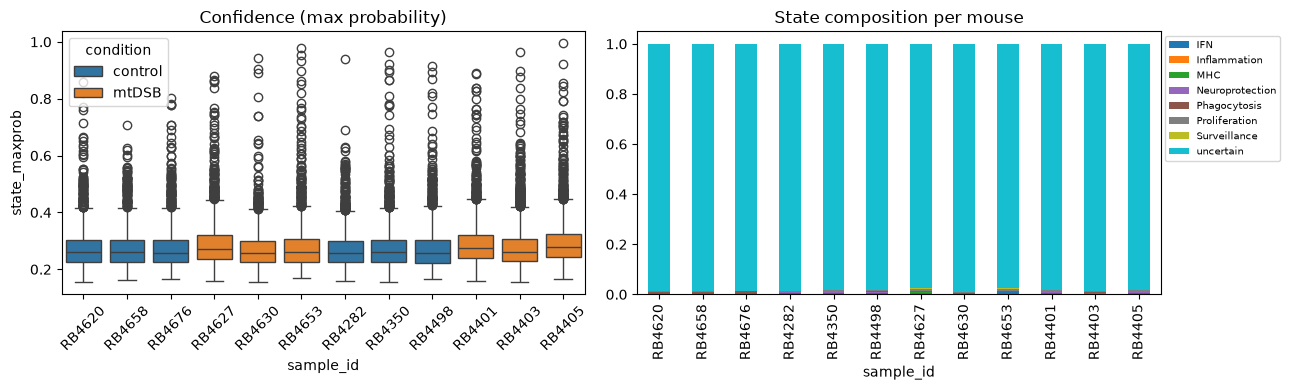

In [9]:
P = pd.concat(probs).loc[q.obs_names]
q.obsm['state_prob'] = P.values
q.uns['state_prob_columns'] = list(P.columns)
q.obs['state_maxprob'] = P.max(1).values
q.obs['state_entropy'] = -(P * np.log(P.clip(lower=1e-12))).sum(1).values
q.obs['mg_state'] = np.where(q.obs['state_maxprob'] >= 0.5, P.idxmax(1).values, 'uncertain')
q.obs['mg_state'] = q.obs['mg_state'].astype('category')

out = pd.concat([q.obs[[SAMPLE, COND, TP, RESP, COMP, 'mg_state', 'state_maxprob', 'state_entropy']], P.add_prefix('p_')], axis=1)
out.to_csv(f'{RES}/microglia_states.csv')
q.write_h5ad('../data/microglia_tangram.h5ad')

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=q.obs, x=SAMPLE, y='state_maxprob', hue=COND, ax=axes[0])
axes[0].tick_params(axis='x', rotation=45); axes[0].set_title('Confidence (max probability)')
comp_ = pd.crosstab(q.obs[SAMPLE], q.obs['mg_state'], normalize='index')
comp_.columns = comp_.columns.astype(str)  # categorical labels break .join in pandas 2.3
comp_.index = comp_.index.astype(str)
comp_.join(q.obs.groupby(SAMPLE, observed=True)[COND].first()).sort_values(COND).drop(columns=COND) \
     .plot.bar(stacked=True, ax=axes[1], colormap='tab10')
axes[1].legend(bbox_to_anchor=(1, 1), fontsize=7); axes[1].set_title('State composition per mouse')
fig.tight_layout(); fig.savefig(f'{RES}/tangram_confidence_composition.png', dpi=150, bbox_inches='tight')
qc

Most microglia cells of the Xenium dataset have all max probability < 0.5. Could be because there are 8 possible states and a cell might be a mix of more. Maybe it's better not to look at the states cell by cell but mouse-wise or compartment-wise.

Consistency check with canonical genes measured directly in Xenium (score per cell, mean per predicted state).
Several of these genes are also training genes, so this is a consistency check, not an independent validation.

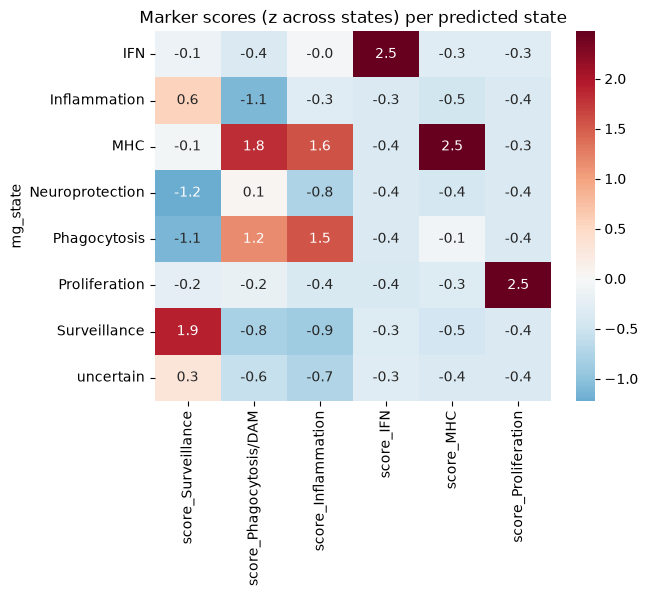

In [10]:
gene_sets = {
    'Surveillance': ['P2ry12', 'Tmem119', 'Sall1', 'Selplg', 'Gpr34', 'Siglech'],
    'Phagocytosis/DAM': ['Cst7', 'Lpl', 'Itgax', 'Axl', 'Clec7a', 'Cd9', 'Trem2', 'Igf1', 'Lgals3'],
    'Inflammation': ['Il1b', 'Tnf', 'Ccl3', 'Ccl4', 'Nfkbia', 'Cd83'],
    'IFN': ['Ifit1', 'Ifit3', 'Isg15', 'Irf7', 'Rsad2', 'Ifitm3'],
    'MHC': ['Cd74', 'H2-Aa', 'H2-Ab1', 'H2-Eb1'],
    'Proliferation': ['Mki67', 'Top2a', 'Ccnb2', 'Cdk1'],
}
for name, genes in gene_sets.items():
    genes = [g for g in genes if g in q.var_names]
    sc.tl.score_genes(q, genes, score_name=f'score_{name}')
scores = q.obs.groupby('mg_state', observed=True)[[f'score_{n}' for n in gene_sets]].mean()
sns.heatmap((scores - scores.mean()) / scores.std(), cmap='RdBu_r', center=0, annot=True, fmt='.1f')
plt.title('Marker scores (z across states) per predicted state')
plt.savefig(f'{RES}/tangram_marker_score_check.png', dpi=150, bbox_inches='tight')

## 6. Microglia states × compartments × condition
One value per mouse; both comparisons (primary mtDSB vs control, permuted within timepoint;
secondary responders vs controls, 84 relabelings), each with a quasi-binomial GLM.
- Microglia per section × compartment are few (~100–300), so the minimum is 50 microglia and rare states are noisy.
- Primary (pre-specified): state fractions over all microglia, and in compartments 3 and 10.
- CM's analysis found microglial MHC-I and DAM gene-set scores up near stressed OLs in responders; the
Tangram states are an independent readout of the same question.

In [11]:
info = cs.sample_table(q.obs, SAMPLE, [COND, TP, RESP])
info['_all'] = 'all'
COMPARISONS = {
    'mtDSB vs control': dict(cond_key=COND, treat='mtDSB', ref='control', strata_key=TP),           # primary
    'responder vs control': dict(cond_key=RESP, treat='responder', ref='control', strata_key='_all'),  # secondary
}

def test_both(long, by, family=None):
    # run test_fractions for each comparison; BH-FDR within comparison (and family)
    out = []
    for name, kw in COMPARISONS.items():
        r = cs.test_fractions(long, info, SAMPLE, by=by, **kw)
        r = r.rename(columns={f"mean_{kw['treat']}": 'mean_treat', f"mean_{kw['ref']}": 'mean_ref'})
        out.append(cs.add_fdr(r, family=family).assign(comparison=name))
    return pd.concat(out, ignore_index=True)

STATES = [s for s in P.columns if (q.obs['mg_state'] == s).sum() >= 100]
print('states tested:', STATES)

q.obs['_section'] = 'all'
st_all = cs.fraction_table(q.obs, SAMPLE, '_section', 'mg_state', STATES, min_cells=50)
st_all_res = test_both(st_all, by=['label'])
st_all_res.to_csv(f'{RES}/test_states_all_microglia.csv', index=False)
display(st_all_res.round(4))

st_comp = cs.fraction_table(q.obs, SAMPLE, COMP, 'mg_state', STATES, min_cells=50)
st_comp_res = test_both(st_comp, by=['label', COMP], family='label')
st_comp_res['primary'] = st_comp_res[COMP].isin(['3', '10'])
st_comp_res.to_csv(f'{RES}/test_states_per_compartment.csv', index=False)
display(st_comp_res[st_comp_res['primary']].sort_values(['comparison', 'label']).round(4))

states tested: ['IFN', 'Proliferation']


,label,mean_ref,mean_treat,effect,p_perm,n_perm,n_treat,n_ref,logOR,p_qb,padj_perm,padj_qb,comparison
0,IFN,0.0043,0.0044,-0.0637,0.7900,400,6,6,-0.0112,0.9630,0.7900,0.9630,mtDSB vs control
1,Proliferation,0.0033,0.0069,0.8131,0.0300,400,6,6,0.7125,0.0409,0.0600,0.0818,mtDSB vs control
2,IFN,0.0043,0.0047,0.0920,0.4881,84,3,6,0.0948,0.5266,0.4881,0.5266,responder vs control
3,Proliferation,0.0033,0.0079,0.9869,0.0357,84,3,6,0.8807,0.0198,0.0714,0.0397,responder vs control


/home/anitag/anaconda3/envs/karospace311/lib/python3.13/site-packages/statsmodels/genmod/generalized_linear_model.py:1269: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  return self._fit_irls(
/home/anitag/anaconda3/envs/karospace311/lib/python3.13/site-packages/statsmodels/genmod/generalized_linear_model.py:1269: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  return self._fit_irls(
/home/anitag/anaconda3/envs/karospace311/lib/python3.13/site-packages/statsmodels/genmod/generalized_linear_model.py:1269: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  return self._fit_irls(
/home/anitag/anaconda3/envs/karospace311/lib/python3.13/site-packages/statsmodels/genmod/generalized_linear_model.py:1269: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  return self._fit_irls(
/hom

,label,compartment,mean_ref,mean_treat,effect,p_perm,n_perm,n_treat,n_ref,logOR,p_qb,padj_perm,padj_qb,comparison,primary
2,IFN,3,0.0048,0.0032,-0.3493,0.3050,400,6,6,-0.3839,0.4375,0.4938,0.6250,mtDSB vs control,True
7,IFN,10,0.0059,0.0134,0.5133,0.2650,400,6,6,0.8234,0.2592,0.4938,0.5877,mtDSB vs control,True
12,Proliferation,3,0.0027,0.0108,0.5773,0.2250,400,6,6,0.8445,0.3090,0.5625,0.5150,mtDSB vs control,True
17,Proliferation,10,0.0161,0.0132,0.0333,0.9150,400,6,6,-0.1787,0.6794,0.9150,0.7549,mtDSB vs control,True
22,IFN,3,0.0048,0.0054,-0.0778,0.8571,84,3,6,-0.1211,0.8038,0.8929,0.9988,responder vs control,True
26,IFN,10,0.0059,0.0171,0.6186,0.3095,84,3,6,1.2458,0.1176,0.5179,0.5411,responder vs control,True
31,Proliferation,3,0.0027,0.0085,0.3079,0.5833,84,3,6,0.5471,0.5262,0.8724,0.9351,responder vs control,True
35,Proliferation,10,0.0161,0.0131,0.0173,0.9762,84,3,6,-0.1571,0.8025,0.9762,0.9457,responder vs control,True


In [ ]:
d = st_comp[st_comp[COMP].isin(['3', '10'])].astype({COMP: str}).join(info, on=SAMPLE)
cs.strip_by_mouse(d, x=COMP, y='frac', group_key=RESP, tp_key=TP, col='label', order=['3', '10'], sharey=False,
                  height=3, aspect=0.7, fname=f'{RES}/states_primary_compartments_per_mouse.png')

### Microglia states near DA-oligodendrocytes (exploratory)
For each microglia, the distance to the nearest DA-OL in the same section. 
- Per mouse: fraction of non-surveillance
microglia within 50 µm of a DA-OL minus the fraction further away (within-section difference, so slide and section
effects cancel).
- That difference is then compared between groups across mice. Controls have few DA-OLs, so their
values are noisy. Spatial units are assumed to be µm (Xenium centroids).


In [13]:
RADIUS = 50
is_da = (obs_all[CT_WORK] == 'DA-Oligodendrocytes').values
q.obs['dist_DA_OL'] = np.nan
for s in q.obs[SAMPLE].cat.categories:
    da_xy = spatial_all[is_da & (obs_all[SAMPLE] == s).values]
    m = (q.obs[SAMPLE] == s).values
    if len(da_xy) >= 20:
        q.obs.loc[m, 'dist_DA_OL'] = cKDTree(da_xy).query(q.obsm['spatial'][m])[0]

q.obs['near_DA_OL'] = np.where(q.obs['dist_DA_OL'] <= RADIUS, 'near', 'far')
reactive = ~q.obs['mg_state'].isin(['Surveillance', 'uncertain'])
near = (q.obs.assign(reactive=reactive).dropna(subset=['dist_DA_OL'])
        .groupby([SAMPLE, 'near_DA_OL'], observed=True)['reactive'].agg(['mean', 'size']).unstack())
near.columns = [f'reactive_{a}_{b}'.replace('reactive_size', 'n') for a, b in near.columns]
near = near.join(info).join(pd.Series(is_da, index=obs_all.index).groupby(obs_all[SAMPLE], observed=True).sum().rename('n_DA_OL'))
near['near_minus_far'] = near['reactive_mean_near'] - near['reactive_mean_far']
display(near.round(3))
near.to_csv(f'{RES}/reactive_microglia_near_DA_OL.csv')

for name, kw in COMPARISONS.items():
    nm = near[near[kw['cond_key']].isin([kw['treat'], kw['ref']])]
    print(name, cs.stratified_permutation_test(nm['near_minus_far'], nm[kw['cond_key']], nm[kw['strata_key']],
                                               kw['treat'], kw['ref']))

,reactive_mean_far,reactive_mean_near,n_far,n_near,condition,timepoint,responder_status,_all,n_DA_OL,near_minus_far
sample_id,,,,,,,,,,
RB4620,0.012,0.013,2240,76,control,P21,control,all,117,0.001
RB4658,0.014,0.000,1882,38,control,P21,control,all,65,-0.014
RB4676,0.012,0.033,2301,123,control,P21,control,all,219,0.021
RB4627,0.015,0.028,953,1380,mtDSB,P21,responder,all,4642,0.013
RB4630,0.009,0.000,1973,15,mtDSB,P21,non-responder,all,32,-0.009
RB4653,0.020,0.091,1982,66,mtDSB,P21,non-responder,all,81,0.071
RB4282,0.013,0.000,2158,30,control,P60,control,all,37,-0.013
RB4350,0.017,0.035,2046,144,control,P60,control,all,291,0.018
RB4498,0.018,0.050,2145,80,control,P60,control,all,115,0.032


mtDSB vs control {'effect': np.float64(0.011993539018764564), 'p_perm': np.float64(0.475), 'n_perm': 400, 'n_treat': 6, 'n_ref': 6}
responder vs control {'effect': np.float64(0.006875219184336272), 'p_perm': np.float64(0.5238095238095238), 'n_perm': 84, 'n_treat': 3, 'n_ref': 6}


### To discuss
- Thresholds (max probability 0.5, 50 µm)
- Map BAMs (marker-gated perivascular cells) with CAM/MDM?
- Use the CM per-cell ISR score instead of the DA-OL label as the "stressed OL" anchor (can't find the file in the repo)
- Cross-check the Tangram states with a simple classifier for robustness.